# Data Understanding, Preparation & Descriptive Modelling

**Goal.** Summarise and visualise the FinTx-Guard training set, answer a set of exploratory questions about what
distinguishes suspicious (`isFraud = 1`) from legitimate transactions, decide which clean-up / pre-processing steps are
needed, and use clustering to look for account-level behavioural profiles.

**Structure**
1. Setup & first look
2. Data quality audit (missing values, duplicates, ranges, consistency rules)
3. Target variable
4. Univariate distributions
5. Exploratory questions (Q1–Q7)
6. Descriptive modelling — clustering of sender accounts
7. Data cleaning & pre-processing pipeline
8. Summary of findings

## 1. First Look

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy.stats import ks_2samp, chi2_contingency
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.feature_selection import mutual_info_classif

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# blue = legitimate, orange = fraud, gray = base-rate line
LEGIT, FRAUD, GRAY = "#2a78d6", "#eb6834", "#8a8984"
RANDOM_STATE = 42

df = pd.read_csv("FinTx-Guard_train.csv")
display(df.head())
df.info()

,transaction_id,time,date,sender_id,receiver_id,amount,payment_currency,received_currency,sender_bank_location,receiver_bank_location,payment_type,customer_session_duration,account_activity_score,transaction_channel,device_recognized,device_risk_score,verification_score,channel_flag,isFraud
0,76443,09:44:51,2023-04-19,AA49C7A57304F7CF25AFC3B34,A1B80787BB81A17BCF1093FEA,971.580,UK pounds,UK pounds,UK,UK,ACH,200,40.000,POS,0,-1.161,-1.272,0,0
1,13537,18:47:13,2022-11-11,AF929BA0C0E9FDF79640B04DB,AB88EA36C2764248B1083497E,56.000,UK pounds,UK pounds,UK,UK,ACH,308,62.300,Other,0,0.534,0.024,0,0
2,48424,03:00:23,2023-02-09,A1F5681C7C087BB287F571BF9,A77801AFFD4C07AA5C581067B,"7,079.230",UK pounds,UK pounds,UK,UK,Credit card,211,31.000,Other,1,0.393,1.409,0,0
3,77340,13:10:01,2023-04-21,AB298058402D02A7913DB3606,AB4371723703DB467AD2A1946,"25,042.780",UK pounds,UK pounds,UK,NaN,ACH,99,21.200,Other,1,0.934,-2.564,0,0
4,58679,16:16:50,2023-03-05,AECDF0440A068E3C82552C44C,A1CDD50184E01956054934B30,"4,580.900",Albanian lek,UK pounds,Albania,UK,Cross-border,85,29.800,Mobile App,1,0.219,2.443,0,1


<class 'pandas.DataFrame'>
RangeIndex: 100459 entries, 0 to 100458
Data columns (total 19 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   transaction_id             100459 non-null  int64  
 1   time                       100459 non-null  str    
 2   date                       100459 non-null  str    
 3   sender_id                  100459 non-null  str    
 4   receiver_id                100459 non-null  str    
 5   amount                     97425 non-null   float64
 6   payment_currency           100459 non-null  str    
 7   received_currency          100459 non-null  str    
 8   sender_bank_location       95407 non-null   str    
 9   receiver_bank_location     92301 non-null   str    
 10  payment_type               94443 non-null   str    
 11  customer_session_duration  100459 non-null  int64  
 12  account_activity_score     90472 non-null   float64
 13  transaction_channel        96338 non-nul

The dataset has **100,459 transactions** and **19 columns**:

| Group | Columns |
|---|---|
| Identifiers | `transaction_id`, `sender_id`, `receiver_id` |
| Time | `date`, `time` |
| Monetary | `amount`, `payment_currency`, `received_currency` |
| Geography | `sender_bank_location`, `receiver_bank_location` |
| Transaction type / channel | `payment_type`, `transaction_channel`, `channel_flag` |
| Behavioural / device scores | `customer_session_duration`, `account_activity_score`, `device_recognized`, `device_risk_score`, `verification_score` |
| Target | `isFraud` |

In [2]:
NUM = ["amount", "customer_session_duration", "account_activity_score", "device_risk_score", "verification_score"]
CAT = ["payment_currency", "received_currency", "sender_bank_location", "receiver_bank_location",
       "payment_type", "transaction_channel"]
BIN = ["device_recognized", "channel_flag"]
TARGET = "isFraud"

display(df[NUM].describe(percentiles=[.01, .25, .5, .75, .99]).T)
df[CAT + ["sender_id", "receiver_id", "date", "time"]].describe().T

,count,mean,std,min,1%,25%,50%,75%,99%,max
amount,"97,425.000","11,171.769","110,502.473",6.430,64.484,"2,197.340","6,037.960","10,409.390","53,271.398","11,837,365.320"
customer_session_duration,"100,459.000",247.366,232.192,10.000,28.000,105.000,180.000,308.000,"1,161.000","3,600.000"
account_activity_score,"90,472.000",38.335,17.791,0.100,5.700,24.700,37.000,50.800,80.500,98.600
device_risk_score,"95,496.000",0.113,0.999,-4.799,-2.200,-0.562,0.115,0.791,2.430,4.500
verification_score,"100,459.000",-0.021,1.005,-4.404,-2.363,-0.694,-0.016,0.655,2.328,4.166


,count,unique,top,freq
payment_currency,100459,13,UK pounds,95767
received_currency,100459,13,UK pounds,91205
sender_bank_location,95407,18,UK,92009
receiver_bank_location,92301,18,UK,84788
payment_type,94443,7,ACH,19453
transaction_channel,96338,4,Mobile App,43237
sender_id,100459,44595,A7CF757B9920DFC67F84DDDA0,30
receiver_id,100459,74648,A059EC0C0A685B7F6ABB20CCA,40
date,100459,256,2023-02-09,498
time,100459,54363,15:12:37,8


## 2. Data quality audit

### 2.1 Missing values

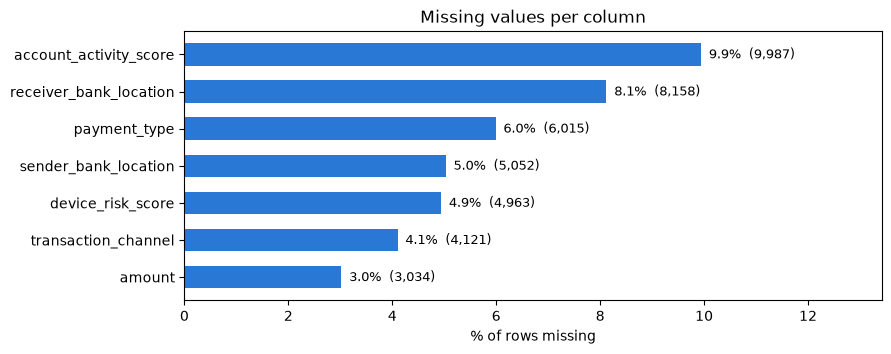

In [3]:
miss = (df.isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.barh(miss.index[::-1], miss.values[::-1], color=LEGIT, height=0.6)
for i, v in enumerate(miss.values[::-1]):
    ax.text(v + 0.15, i, f"{v:.1f}%  ({int(v / 100 * len(df)):,})", va="center", fontsize=9)
ax.set_xlabel("% of rows missing"); ax.set_title("Missing values per column")
ax.set_xlim(0, miss.max() * 1.35); ax.grid(axis="y", visible=False)
plt.show()

There are seven collumns with missing values. To decide how we handle the missing values we need to see how relevant the missing values are.

In [4]:
rows = []
for c in miss.index:
    m = df[c].isna()
    tab = pd.crosstab(m, df[TARGET])
    p = chi2_contingency(tab)[1]
    rows.append({"column": c, "n_missing": m.sum(),
                 "fraud_rate_missing": df.loc[m, TARGET].mean(),
                 "fraud_rate_present": df.loc[~m, TARGET].mean(), "chi2_p_value": p})

display(pd.DataFrame(rows).set_index("column"))
print("Rows with at least one missing value:", f"{df.isna().any(axis=1).mean():.1%}")

,n_missing,fraud_rate_missing,fraud_rate_present,chi2_p_value
column,,,,
account_activity_score,9987,0.075,0.077,0.349
receiver_bank_location,8158,0.077,0.077,0.959
payment_type,6016,0.077,0.077,0.954
sender_bank_location,5052,0.083,0.077,0.138
device_risk_score,4963,0.077,0.077,0.925
transaction_channel,4121,0.073,0.077,0.314
amount,3034,0.087,0.077,0.033


Rows with at least one missing value: 34.7%


Missingness is essentially **not related to fraud** (fraud rate ≈ 7.7% whether present or not). The only different case is `amount` (8.7% vs 7.7%, p = 0.03). Rows with missing values will therefore be **kept and imputed** (dropping every incomplete row would discard ~35% of the data):

| Column | % missing | Imputation |
|---|---|---|
| `amount` | 3.0% | Median **of the same `payment_type`** + missing indicator `amount_missing` |
| `sender_bank_location` | 5.0% | `UK` if `payment_currency` is GBP, otherwise `Unknown` + missing indicator |
| `receiver_bank_location` | 8.1% | `UK` if `received_currency` is GBP, otherwise `Unknown` + missing indicator |
| `payment_type` | 6.0% | `Cross-border` if sender and receiver locations are known and different, otherwise `Unknown` |
| `transaction_channel` | 4.1% | New category `Unknown` |
| `account_activity_score` | 9.9% | Global median |
| `device_risk_score` | 4.9% | Global median |


### 2.2 Duplicates, identifiers and value ranges

In [5]:
print("Fully duplicated rows:            ", df.duplicated().sum())
print("Duplicated transaction_id:        ", df.transaction_id.duplicated().sum())
print("Duplicates ignoring transaction_id:", df.drop(columns="transaction_id").duplicated().sum())
print("Self-transfers (sender == receiver):", (df.sender_id == df.receiver_id).sum())
print("Non-positive amounts:             ", (df.amount <= 0).sum())
print("Unparseable times:                ", pd.to_datetime(df.time, format="%H:%M:%S", errors="coerce").isna().sum())
print("Unparseable dates:                ", pd.to_datetime(df.date, errors="coerce").isna().sum())
print("Date range:", df.date.min(), "->", df.date.max())
print("Session duration range (s):", df.customer_session_duration.min(), "-", df.customer_session_duration.max(),
      "| rows at the 3600 s cap:", (df.customer_session_duration == 3600).sum())
print(f"Unique senders: {df.sender_id.nunique():,} | unique receivers: {df.receiver_id.nunique():,} | "
      f"receivers that also send: {df.receiver_id.drop_duplicates().isin(df.sender_id).mean():.1%}")

Fully duplicated rows:             0
Duplicated transaction_id:         0
Duplicates ignoring transaction_id: 0
Self-transfers (sender == receiver): 0
Non-positive amounts:              0


Unparseable times:                 0
Unparseable dates:                 0
Date range: 2022-10-07 -> 2023-06-19
Session duration range (s): 10 - 3600 | rows at the 3600 s cap: 6
Unique senders: 44,595 | unique receivers: 74,648 | receivers that also send: 16.4%


There are no duplicates rows or impossible values.

In [6]:
both_known = df.sender_bank_location.notna() & df.receiver_bank_location.notna()
df_chk = df[both_known].assign(diff_location=lambda d: d.sender_bank_location != d.receiver_bank_location,
                               diff_currency=lambda d: d.payment_currency != d.received_currency)
pd.concat([pd.crosstab(df_chk.payment_type.fillna("<missing>"), df_chk.diff_location).add_prefix("diff_location="),
           pd.crosstab(df_chk.payment_type.fillna("<missing>"), df_chk.diff_currency).add_prefix("diff_currency=")], axis=1)

,diff_location=False,diff_location=True,diff_currency=False,diff_currency=True
payment_type,,,,
<missing>,4706,565,4608,663
ACH,16984,0,16585,399
Cash Deposit,2642,0,2604,38
Cash Withdrawal,3037,259,3037,259
Cheque,16775,0,16354,421
Credit card,16762,0,16386,376
Cross-border,0,9109,53,9056
Debit card,16844,0,16437,407


When both locations are known, every `Cross-border` payment is between two different countries, and 97% of payments between two countries are `Cross-border`. This supports imputing a missing `payment_type` as `Cross-border` when the locations differ.

In [7]:
print("Median amount by payment currency:")
print(df.groupby("payment_currency").amount.median().round(0).sort_values().to_string())

Median amount by payment currency:
payment_currency
UK pounds         5,968.000
Turkish lira      6,883.000
Pakistani rupee   7,058.000
Naira             7,076.000
Indian rupee      7,290.000
Swiss franc       7,302.000
Yen               7,379.000
Moroccan dirham   7,429.000
Dirham            7,454.000
Albanian lek      7,489.000
Euro              7,559.000
US dollar         7,573.000
Mexican Peso      7,801.000


## 3. Target variable

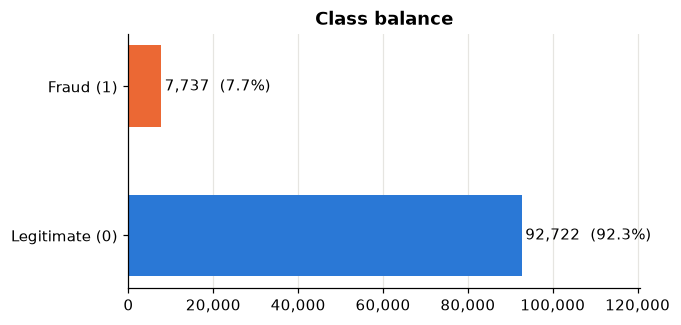

Base fraud rate: 7.70%  -> imbalance ratio ~ 1:12


In [34]:
counts = df[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(["Legitimate (0)", "Fraud (1)"], counts.values, color=[LEGIT, FRAUD], height=0.55)
for i, v in enumerate(counts.values):
    ax.text(v + 800, i, f"{v:,}  ({v / counts.sum():.1%})", va="center")
ax.set_xlim(0, counts.max() * 1.3); ax.set_title("Class balance"); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
plt.show()
BASE_RATE = df[TARGET].mean()
print(f"Base fraud rate: {BASE_RATE:.2%}  -> imbalance ratio ~ 1:{(1 - BASE_RATE) / BASE_RATE:.0f}")

The target is **imbalanced (7.7% fraud, ~1:12)**, so later we need stratified splits and metrics like F1 / PR-AUC instead of accuracy. The dashed gray line in the charts below marks this base rate.

## 4. Distributions

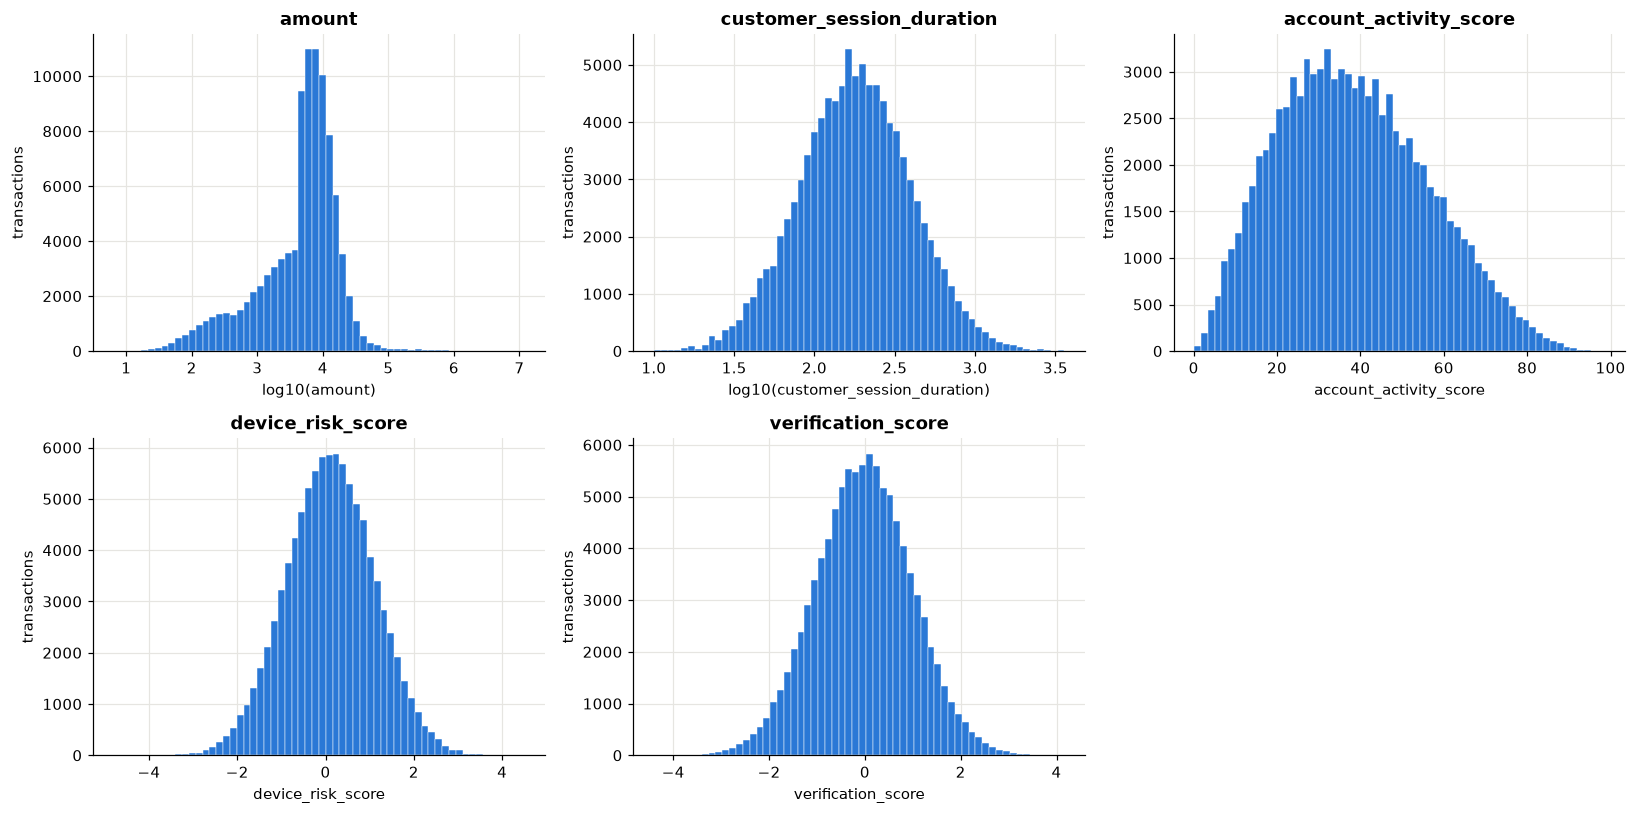

In [35]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
plot_cols = [("amount", True), ("customer_session_duration", True), ("account_activity_score", False),
             ("device_risk_score", False), ("verification_score", False)]
for ax, (c, logx) in zip(axes.flat, plot_cols):
    x = df[c].dropna()
    if logx:
        x = np.log10(x); ax.set_xlabel(f"log10({c})")
    else:
        ax.set_xlabel(c)
    ax.hist(x, bins=60, color=LEGIT, edgecolor="white", linewidth=0.3)
    ax.set_title(c); ax.set_ylabel("transactions")
axes.flat[-1].axis("off")
plt.tight_layout(); plt.show()

`amount` and `customer_session_duration` are strongly right-skewed (log scale needed). The scores are bell-shaped; `device_risk_score` and `verification_score` look already standardised.

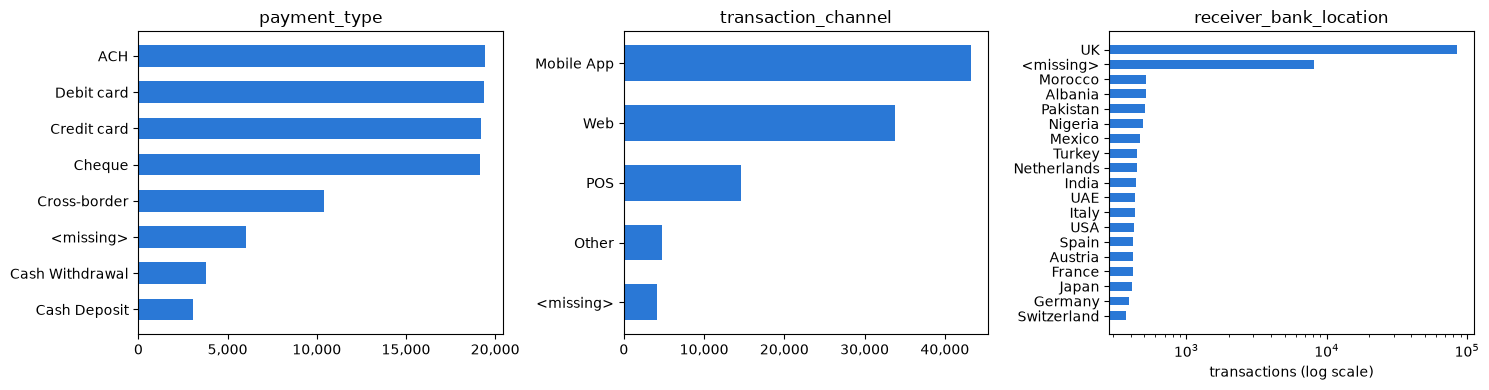

Share of transactions in GBP (payment): 95.3%; sender in UK: 91.6%


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ["payment_type", "transaction_channel", "receiver_bank_location"]):
    vc = df[c].fillna("<missing>").value_counts()
    ax.barh(vc.index[::-1], vc.values[::-1], color=LEGIT, height=0.6)
    ax.set_title(c); ax.grid(axis="y", visible=False); ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
    if c == "receiver_bank_location":
        ax.set_xscale("log"); ax.set_xlabel("transactions (log scale)")
plt.tight_layout(); plt.show()
print(f"Share of transactions in GBP (payment): {(df.payment_currency == 'UK pounds').mean():.1%}; "
      f"sender in UK: {(df.sender_bank_location == 'UK').mean():.1%}")

Most activity is domestic UK (95% paid in GBP). Card, ACH and cheque payments make up ~19% each, cross-border 10% and cash 7%.

## 5. Exploratory questions

Orange bars are above the base fraud rate (dashed line), blue bars below.

In [26]:
def fraud_rate_plot(data, col, ax=None, top=None, title=None, min_n=0):
    g = data.groupby(data[col].astype(object).fillna("<missing>"), observed=True)[TARGET].agg(["mean", "size"])
    g = g[g["size"] >= min_n].sort_values("mean")
    if top: g = g.tail(top)
    ax = ax or plt.gca()
    colors = [FRAUD if m > BASE_RATE else LEGIT for m in g["mean"]]
    ax.barh(g.index.astype(str), g["mean"], color=colors, height=0.6)
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(m + 0.004, i, f"{m:.1%}  (n={n:,})", va="center", fontsize=8.5)
    ax.axvline(BASE_RATE, color=GRAY, ls="--", lw=1.2)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_xlim(0, g["mean"].max() * 1.4)
    ax.set_xlabel("fraud rate"); ax.set_title(title or f"Fraud rate by {col}"); ax.grid(axis="y", visible=False)
    return g

### Q1. Which payment types and channels are riskiest?

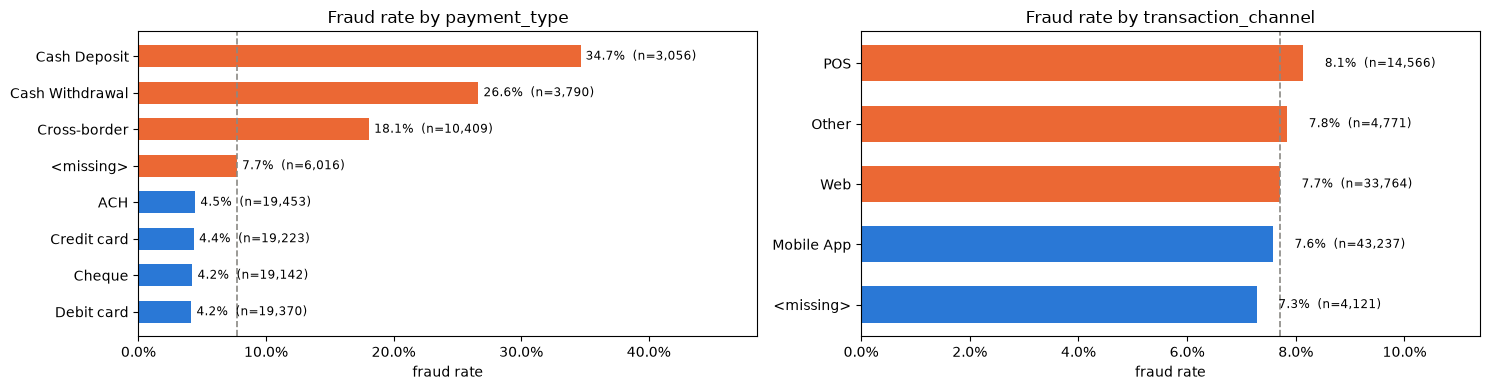

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
fraud_rate_plot(df, "payment_type", ax=axes[0])
fraud_rate_plot(df, "transaction_channel", ax=axes[1])
plt.tight_layout(); plt.show()

* **Cash deposits (34.7%), cash withdrawals (26.6%) and cross-border payments (18.1%)** are far riskier than card, ACH and cheque (~4.3%).
* The channel makes no difference (7.3–8.1%).

### Q2. Are international transactions riskier? Which countries/currencies?

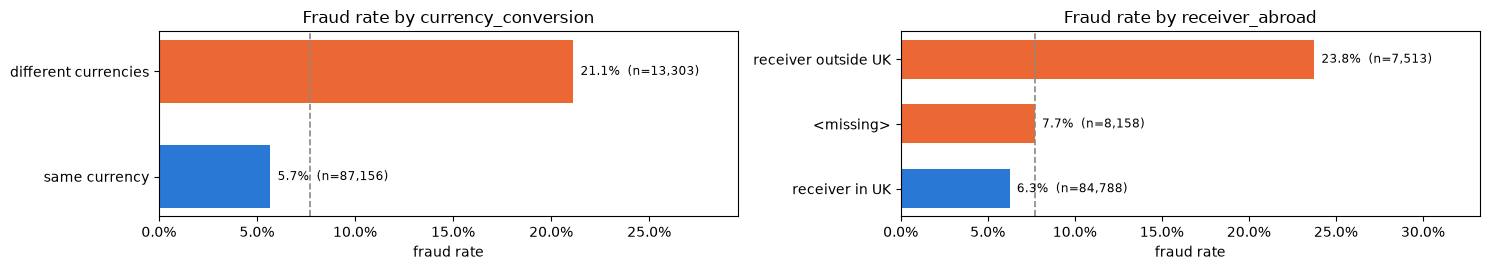

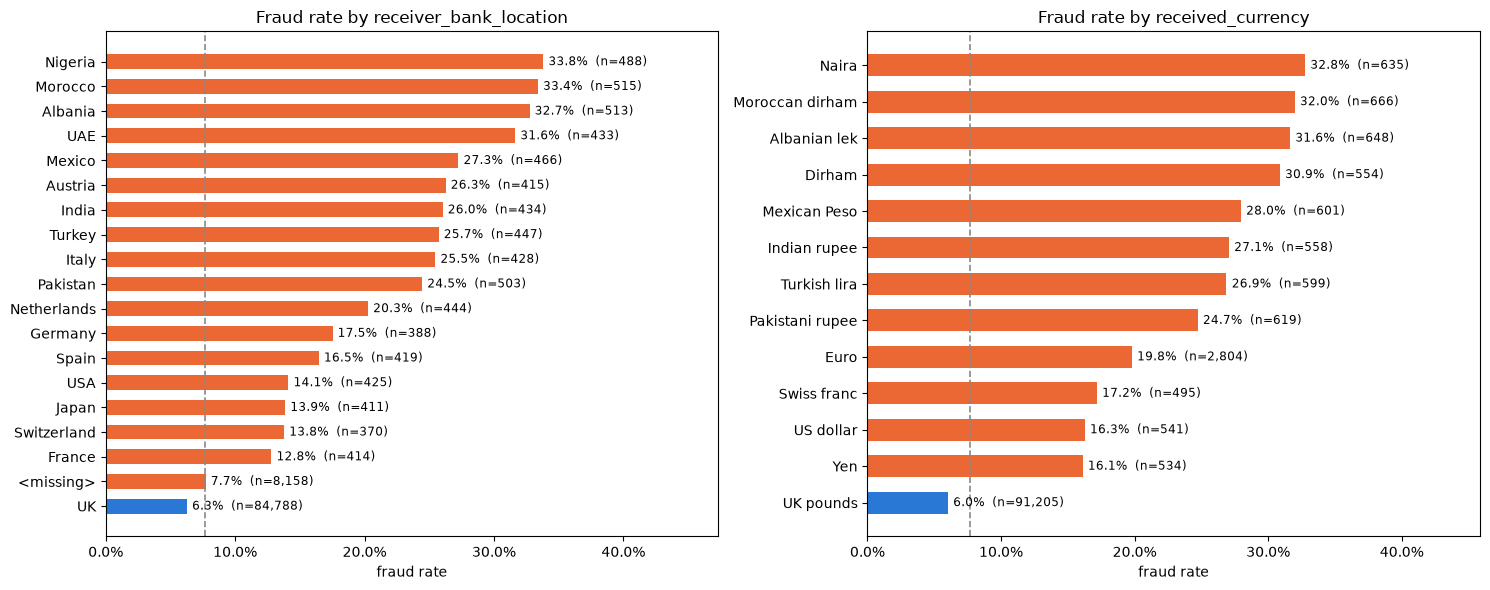

In [13]:
d2 = df.assign(
    currency_conversion=np.where(df.payment_currency != df.received_currency, "different currencies", "same currency"),
    receiver_abroad=np.where(df.receiver_bank_location.isna(), "<missing>",
                             np.where(df.receiver_bank_location != "UK", "receiver outside UK", "receiver in UK")))
fig, axes = plt.subplots(1, 2, figsize=(15, 2.8))
fraud_rate_plot(d2, "currency_conversion", ax=axes[0])
fraud_rate_plot(d2, "receiver_abroad", ax=axes[1])
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fraud_rate_plot(df, "receiver_bank_location", ax=axes[0])
fraud_rate_plot(df, "received_currency", ax=axes[1])
plt.tight_layout(); plt.show()

* Currency conversion: **21.1% vs 5.7%** fraud. Receiver outside the UK: **23.8% vs 6.3%**.
* Riskiest destinations: **Nigeria, Morocco, Albania and the UAE** (>30%).

### Q3. Do fraudulent transactions involve different amounts?

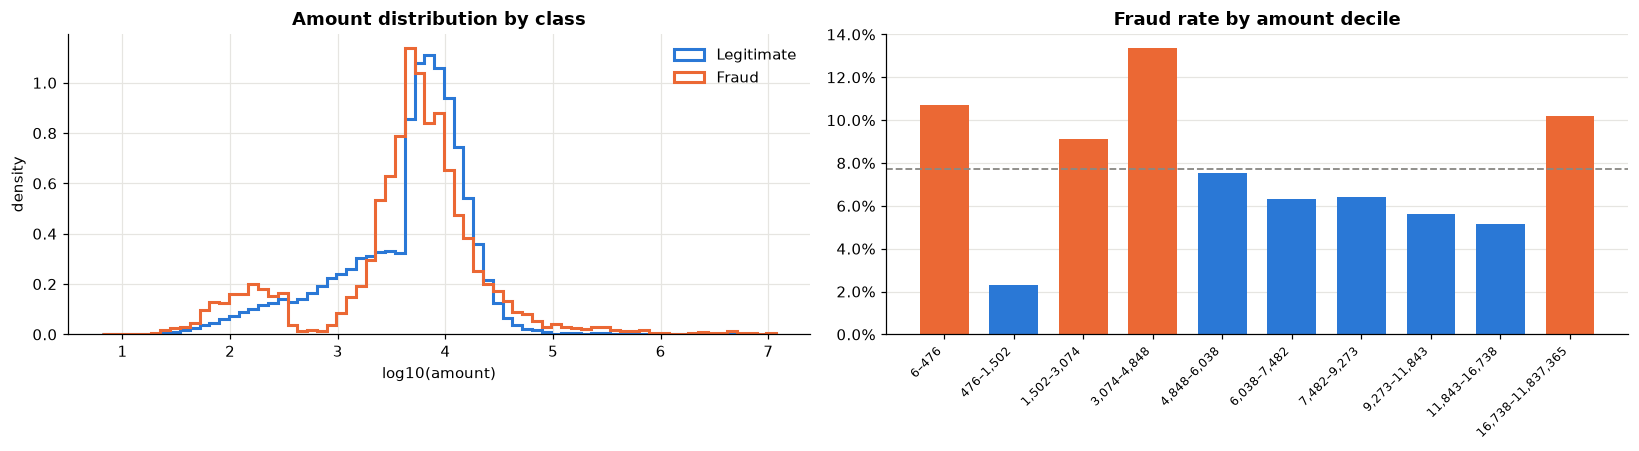

Amount > 99.0% quantile (53,271): fraud rate 32.5%
Amount > 99.9% quantile (573,318): fraud rate 67.3%
isFraud          median_legit  median_fraud
payment_type                               
ACH                 6,290.900     7,666.027
Cash Deposit        1,724.600     3,018.550
Cash Withdrawal       136.970       138.630
Cheque              6,410.475     7,507.905
Credit card         6,360.300     7,903.470
Cross-border        7,428.390     5,831.190
Debit card          6,351.680     7,829.870


In [36]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
bins = np.linspace(np.log10(df.amount.min()), np.log10(df.amount.max()), 70)
for lab, col, name in [(0, LEGIT, "Legitimate"), (1, FRAUD, "Fraud")]:
    axes[0].hist(np.log10(df.loc[df[TARGET] == lab, "amount"].dropna()), bins=bins, density=True,
                 histtype="step", lw=2, color=col, label=name)
axes[0].set_xlabel("log10(amount)"); axes[0].set_ylabel("density"); axes[0].legend()
axes[0].set_title("Amount distribution by class")

dec = df.assign(amount_decile=pd.qcut(df.amount, 10))
g = dec.groupby("amount_decile", observed=True)[TARGET].mean()
labels = [f"{iv.left:,.0f}–{iv.right:,.0f}" for iv in g.index]
axes[1].bar(range(10), g.values, color=[FRAUD if v > BASE_RATE else LEGIT for v in g.values], width=0.7)
axes[1].axhline(BASE_RATE, color=GRAY, ls="--", lw=1.2)
axes[1].set_xticks(range(10)); axes[1].set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); axes[1].set_title("Fraud rate by amount decile")
axes[1].grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

for q in [.99, .999]:
    thr = df.amount.quantile(q)
    print(f"Amount > {q:.1%} quantile ({thr:,.0f}): fraud rate {df.loc[df.amount > thr, TARGET].mean():.1%}")
print(df.groupby(["payment_type", TARGET]).amount.median().unstack().rename(columns={0: "median_legit", 1: "median_fraud"}))

* Amounts under 476 (10.7%) and 3,000–4,850 (13.3%) are riskier, while 476–1,500 is almost fraud-free (2.3%).
* Extreme amounts are the riskiest, with **33%** fraud above the 99th percentile, **67%** above the 99.9th, so these outliers are kept.

### Q4. Are there temporal patterns?

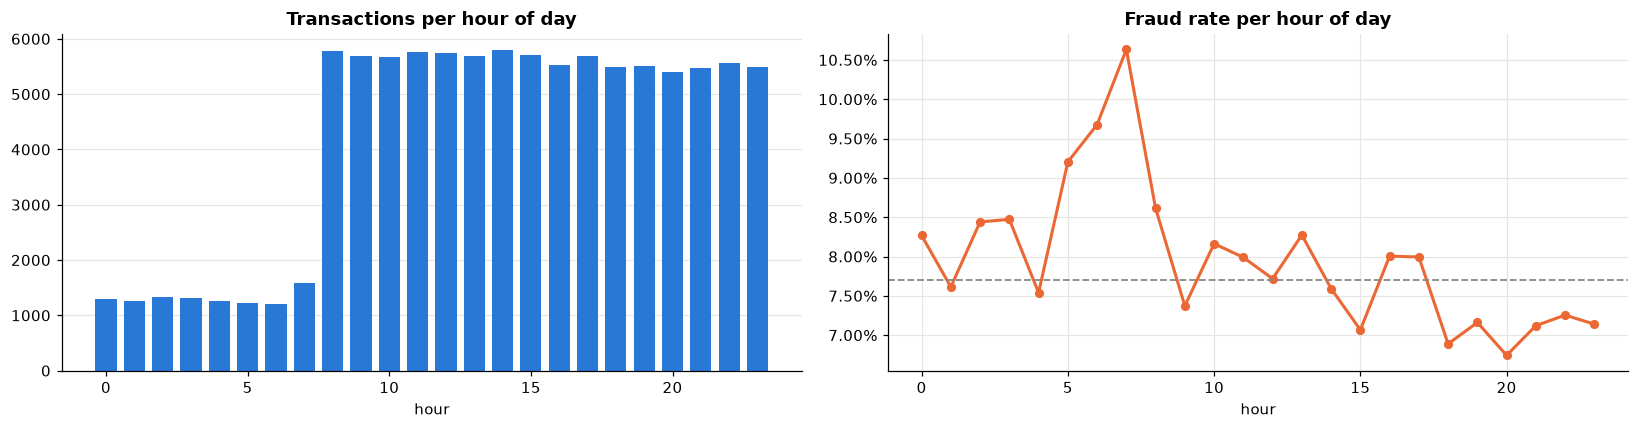

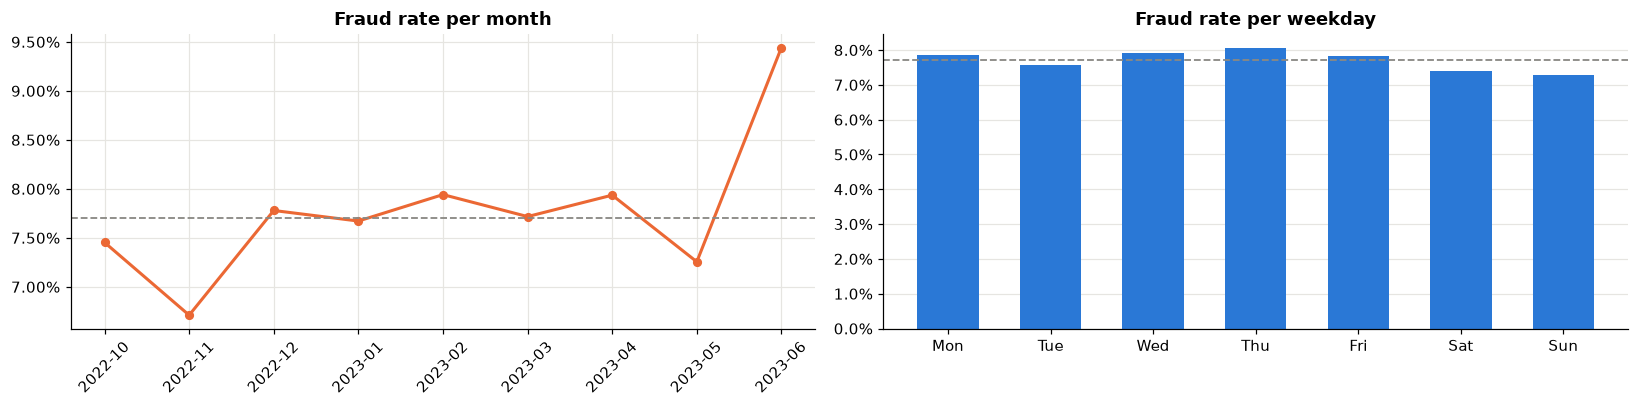

Rows per month: {'2022-10': 9311, '2022-11': 11831, '2022-12': 11659, '2023-01': 12253, '2023-02': 11912, '2023-03': 12012, '2023-04': 12122, '2023-05': 11935, '2023-06': 7424}


In [37]:
dt = pd.to_datetime(df.date + " " + df.time)
tmp = df.assign(hour=dt.dt.hour, weekday=dt.dt.day_name().str[:3], month=dt.dt.to_period("M").astype(str))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
h = tmp.groupby("hour")[TARGET].agg(["mean", "size"])
axes[0].bar(h.index, h["size"], color=LEGIT, width=0.75)
axes[0].set_title("Transactions per hour of day"); axes[0].set_xlabel("hour"); axes[0].grid(axis="x", visible=False)
axes[1].plot(h.index, h["mean"], color=FRAUD, lw=2, marker="o", ms=5)
axes[1].axhline(BASE_RATE, color=GRAY, ls="--", lw=1.2)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].set_title("Fraud rate per hour of day"); axes[1].set_xlabel("hour")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
m = tmp.groupby("month")[TARGET].agg(["mean", "size"])
axes[0].plot(m.index, m["mean"], color=FRAUD, lw=2, marker="o", ms=5)
axes[0].axhline(BASE_RATE, color=GRAY, ls="--", lw=1.2); axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[0].set_title("Fraud rate per month"); axes[0].tick_params(axis="x", rotation=45)
w = tmp.groupby("weekday")[TARGET].mean().reindex(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[1].bar(w.index, w.values, color=LEGIT, width=0.6); axes[1].axhline(BASE_RATE, color=GRAY, ls="--", lw=1.2)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); axes[1].set_title("Fraud rate per weekday")
axes[1].grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
print("Rows per month:", m["size"].to_dict())

* Fraud is slightly higher early in the morning (05:00–07:59, 9–11%); the weekday has no real effect.
* The fraud rate is stable across months (6.7–7.9%) except June 2023 (9.4%).

### Q5. Do the behavioural and device scores separate fraud from legitimate transactions?

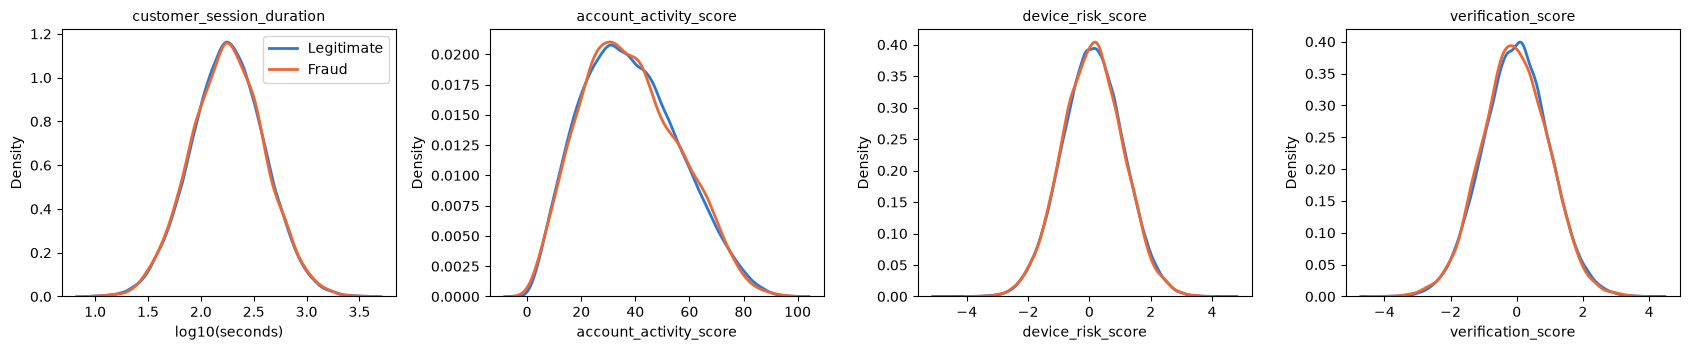

,mean_legit,mean_fraud,KS_stat,p_value
feature,,,,
customer_session_duration,2.255,2.253,0.008,0.683
account_activity_score,38.339,38.286,0.010,0.515
device_risk_score,0.115,0.099,0.013,0.226
verification_score,-0.018,-0.052,0.021,0.004
amount (reference),NaN,NaN,0.072,0.000


In [16]:
score_cols = ["customer_session_duration", "account_activity_score", "device_risk_score", "verification_score"]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
rows = []
for ax, c in zip(axes, score_cols):
    a, b = df.loc[df[TARGET] == 0, c].dropna(), df.loc[df[TARGET] == 1, c].dropna()
    if c == "customer_session_duration":
        a, b = np.log10(a), np.log10(b); ax.set_xlabel("log10(seconds)")
    sns.kdeplot(a, ax=ax, color=LEGIT, lw=2, label="Legitimate")
    sns.kdeplot(b, ax=ax, color=FRAUD, lw=2, label="Fraud")
    ax.set_title(c, fontsize=10)
    ks = ks_2samp(a, b)
    rows.append({"feature": c, "mean_legit": a.mean(), "mean_fraud": b.mean(), "KS_stat": ks.statistic, "p_value": ks.pvalue})
axes[0].legend()
plt.tight_layout(); plt.show()
ks_amt = ks_2samp(df.loc[df[TARGET] == 0, "amount"].dropna(), df.loc[df[TARGET] == 1, "amount"].dropna())
rows.append({"feature": "amount (reference)", "KS_stat": ks_amt.statistic, "p_value": ks_amt.pvalue})
pd.DataFrame(rows).set_index("feature")

The four scores have **almost identical distributions for fraud and legitimate transactions** (KS ≤ 0.02, vs 0.07 for `amount`), so on their own they don't help detect fraud.

### Q6. Do account-level patterns reveal fraud?

For each transaction we count how many transactions its sender, its receiver and the sender→receiver pair have in the dataset.

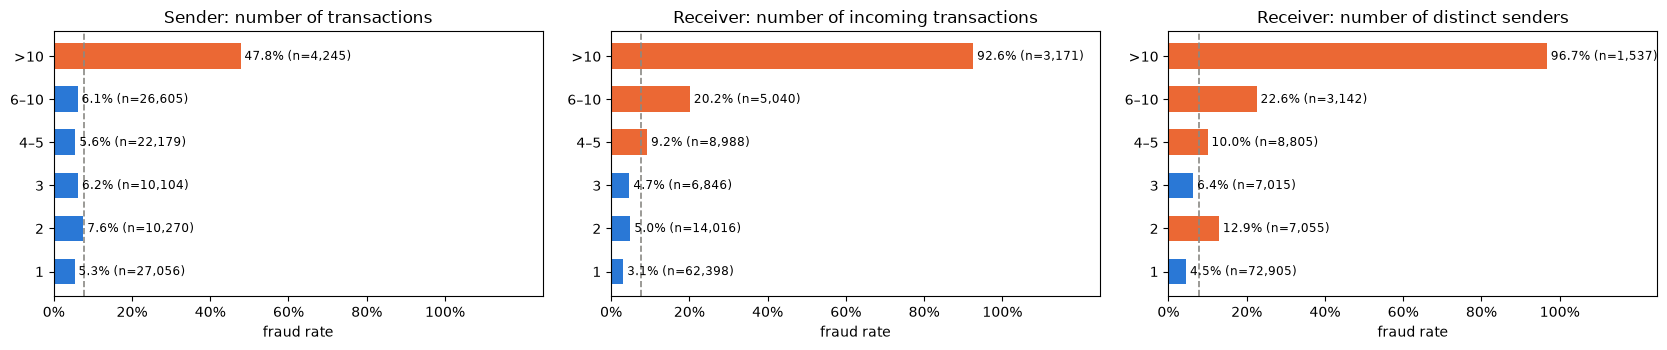

In [17]:
acc = df.copy()
acc["sender_tx_count"] = acc.groupby("sender_id")["transaction_id"].transform("size")
acc["sender_unique_receivers"] = acc.groupby("sender_id")["receiver_id"].transform("nunique")
acc["receiver_tx_count"] = acc.groupby("receiver_id")["transaction_id"].transform("size")
acc["receiver_unique_senders"] = acc.groupby("receiver_id")["sender_id"].transform("nunique")
acc["pair_tx_count"] = acc.groupby(["sender_id", "receiver_id"])["transaction_id"].transform("size")

edges = [0, 1, 2, 3, 5, 10, 1000]
labels = ["1", "2", "3", "4–5", "6–10", ">10"]
fig, axes = plt.subplots(1, 3, figsize=(17, 3.6))
for ax, c, t in [(axes[0], "sender_tx_count", "Sender: number of transactions"),
                 (axes[1], "receiver_tx_count", "Receiver: number of incoming transactions"),
                 (axes[2], "receiver_unique_senders", "Receiver: number of distinct senders")]:
    # bars kept in bucket order (not sorted by rate) to show the trend
    g = acc.groupby(pd.cut(acc[c], edges, labels=labels), observed=True)[TARGET].agg(["mean", "size"])
    ax.barh(g.index.astype(str), g["mean"], color=[FRAUD if m > BASE_RATE else LEGIT for m in g["mean"]], height=0.6)
    for i, (mm, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(mm + 0.01, i, f"{mm:.1%} (n={n:,})", va="center", fontsize=8.5)
    ax.axvline(BASE_RATE, color=GRAY, ls="--", lw=1.2); ax.set_xlim(0, 1.25); ax.set_xticks(np.arange(0, 1.01, 0.2))
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_title(t); ax.grid(axis="y", visible=False)
    ax.set_xlabel("fraud rate")
plt.tight_layout(); plt.show()

In [18]:
g = acc.groupby("pair_tx_count")[TARGET].agg(["mean", "size"]).rename(columns={"mean": "fraud_rate", "size": "n_tx"})
print("Fraud rate by number of transactions between the same sender→receiver pair:")
g.head(12)

Fraud rate by number of transactions between the same sender→receiver pair:


,fraud_rate,n_tx
pair_tx_count,,
1,0.069,85880
2,0.000,11494
3,0.000,1140
4,0.229,140
5,0.714,70
6,1.000,66
7,1.000,84
8,1.000,64
9,1.000,36


This is the **strongest signal** in the data:
* Receivers with more than 10 incoming transactions: **93% fraud** (money-mule accounts). Senders with more than 10 transactions: 48%.
* Same sender→receiver pair: 2–3 transactions → 0% fraud, **6 or more → 100%**.

**Caveat:** these counts use the whole dataset. For modelling they must be computed from past transactions only, to avoid leakage.

### Q7. Overall: which variables carry the most information about fraud?

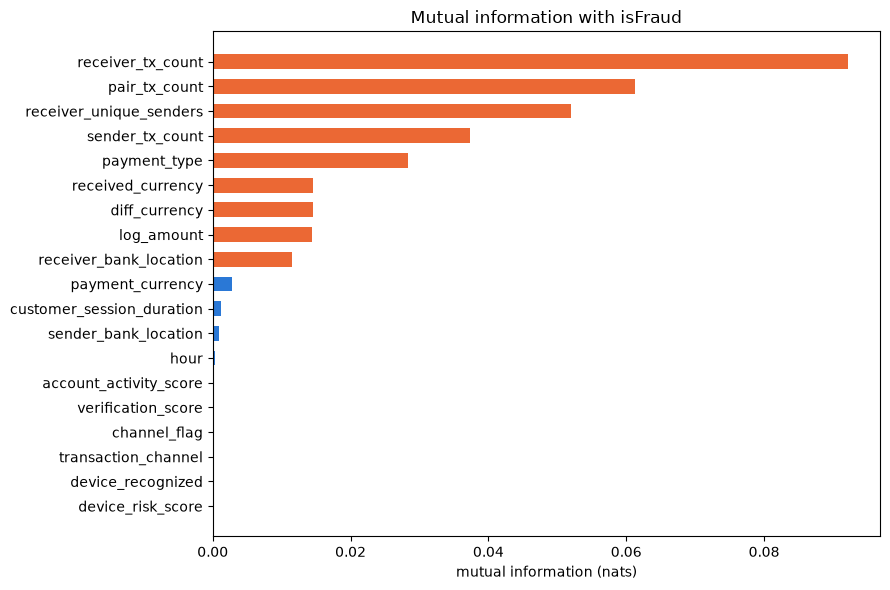

In [19]:
mi_df = acc.copy()
mi_df["log_amount"] = np.log1p(mi_df["amount"])
mi_df["hour"] = dt.dt.hour
mi_df["diff_currency"] = (mi_df.payment_currency != mi_df.received_currency).astype(int)
mi_features = ["log_amount", "customer_session_duration", "account_activity_score", "device_risk_score",
               "verification_score", "device_recognized", "channel_flag", "hour", "diff_currency",
               "payment_type", "transaction_channel", "payment_currency", "received_currency",
               "sender_bank_location", "receiver_bank_location",
               "sender_tx_count", "receiver_tx_count", "receiver_unique_senders", "pair_tx_count"]
X = mi_df[mi_features].copy()
discrete = []
for c in X.columns:
    if X[c].dtype == object or str(X[c].dtype) in ("str", "string"):
        X[c] = X[c].fillna("<missing>").astype("category").cat.codes
        discrete.append(True)
    else:
        X[c] = X[c].fillna(X[c].median())
        discrete.append(c in ["device_recognized", "channel_flag", "hour", "diff_currency"])
mi = pd.Series(mutual_info_classif(X, mi_df[TARGET], discrete_features=discrete, random_state=RANDOM_STATE),
               index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(mi.index, mi.values, color=[FRAUD if v > 0.01 else LEGIT for v in mi.values], height=0.6)
ax.set_title("Mutual information with isFraud"); ax.set_xlabel("mutual information (nats)"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

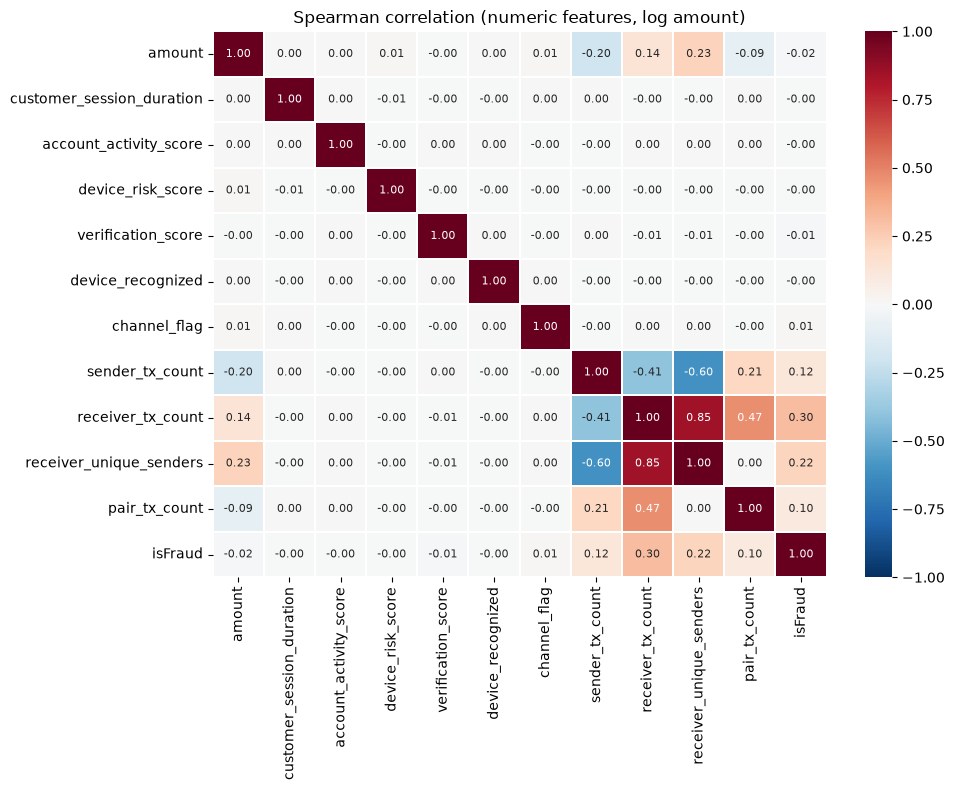

In [20]:
num_corr = acc[NUM + BIN + ["sender_tx_count", "receiver_tx_count", "receiver_unique_senders", "pair_tx_count", TARGET]].copy()
num_corr["amount"] = np.log1p(num_corr["amount"])
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(num_corr.corr(method="spearman"), cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 8}, linewidths=0.3, ax=ax)
ax.set_title("Spearman correlation (numeric features, log amount)")
plt.tight_layout(); plt.show()

Account-level counts carry the most information, followed by payment type, currency/destination and amount. The scores, channel and `device_recognized` carry almost none, and the original numeric features are uncorrelated with each other.

## 6. Clustering sender accounts

Each sender is described by its activity (number of transactions and receivers, amounts) and the share of its transactions that are cash, cross-border, in another currency, to a receiver abroad or at night. We then apply K-Means. The fraud label is only used afterwards, to compare the clusters.

In [21]:
cl = df.assign(
    hour=dt.dt.hour,
    is_cash=df.payment_type.isin(["Cash Deposit", "Cash Withdrawal"]).astype(int),
    is_cross_border=(df.payment_type == "Cross-border").astype(int),
    diff_currency=(df.payment_currency != df.received_currency).astype(int),
    receiver_abroad=(df.receiver_bank_location.notna() & (df.receiver_bank_location != "UK")).astype(int),
    log_amount=np.log1p(df.amount),
)
cl["is_night"] = (cl.hour < 8).astype(int)

senders = cl.groupby("sender_id").agg(
    n_tx=("transaction_id", "size"),
    n_receivers=("receiver_id", "nunique"),
    mean_log_amount=("log_amount", "mean"),
    max_log_amount=("log_amount", "max"),
    share_cash=("is_cash", "mean"),
    share_cross_border=("is_cross_border", "mean"),
    share_diff_currency=("diff_currency", "mean"),
    share_receiver_abroad=("receiver_abroad", "mean"),
    share_night=("is_night", "mean"),
    fraud_rate=(TARGET, "mean"),           # NOT used for clustering, only for profiling
)
senders["any_fraud"] = (senders.fraud_rate > 0).astype(int)
senders[["mean_log_amount", "max_log_amount"]] = senders[["mean_log_amount", "max_log_amount"]].fillna(
    senders[["mean_log_amount", "max_log_amount"]].median())

CL_FEATURES = ["n_tx", "n_receivers", "mean_log_amount", "max_log_amount", "share_cash", "share_cross_border",
               "share_diff_currency", "share_receiver_abroad", "share_night"]
Xc = senders[CL_FEATURES].copy()
Xc[["n_tx", "n_receivers"]] = np.log1p(Xc[["n_tx", "n_receivers"]])
Xs = StandardScaler().fit_transform(Xc)
print(f"{len(senders):,} sender accounts x {len(CL_FEATURES)} features")

44,595 sender accounts x 9 features


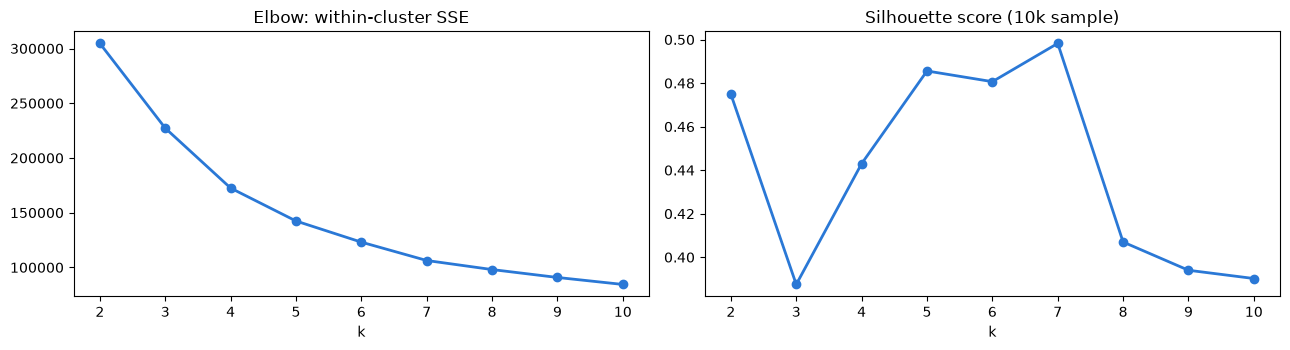

{2: 0.475, 3: 0.387, 4: 0.443, 5: 0.486, 6: 0.481, 7: 0.498, 8: 0.407, 9: 0.394, 10: 0.39}


In [22]:
ks = range(2, 11)
inertia, sil = [], []
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(len(Xs), size=10_000, replace=False)
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xs)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Xs[sample_idx], km.labels_[sample_idx]))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].plot(list(ks), inertia, marker="o", color=LEGIT, lw=2); axes[0].set_title("Elbow: within-cluster SSE")
axes[1].plot(list(ks), sil, marker="o", color=LEGIT, lw=2); axes[1].set_title("Silhouette score (10k sample)")
for ax in axes: ax.set_xlabel("k")
plt.tight_layout(); plt.show()
print(pd.Series(sil, index=list(ks)).round(3).to_dict())

In [38]:
K = int(pd.Series(sil, index=list(ks)).idxmax())   # k with the best silhouette
km = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(Xs)
senders["cluster"] = km.labels_
print("Chosen k =", K)

profile = senders.groupby("cluster").agg(
    n_senders=("n_tx", "size"),
    n_tx_mean=("n_tx", "mean"), n_receivers_mean=("n_receivers", "mean"),
    amount_median=("mean_log_amount", lambda x: np.expm1(x.median())),
    share_cash=("share_cash", "mean"), share_cross_border=("share_cross_border", "mean"),
    share_diff_currency=("share_diff_currency", "mean"), share_receiver_abroad=("share_receiver_abroad", "mean"),
    share_night=("share_night", "mean"),
    senders_with_fraud=("any_fraud", "mean"),
)
tx_fraud = cl.assign(cluster=cl.sender_id.map(senders.cluster)).groupby("cluster")[TARGET].agg(["mean", "size"])
profile["n_transactions"] = tx_fraud["size"]
profile["tx_fraud_rate"] = tx_fraud["mean"]
profile.sort_values("tx_fraud_rate", ascending=False)

NameError: name 'sil' is not defined

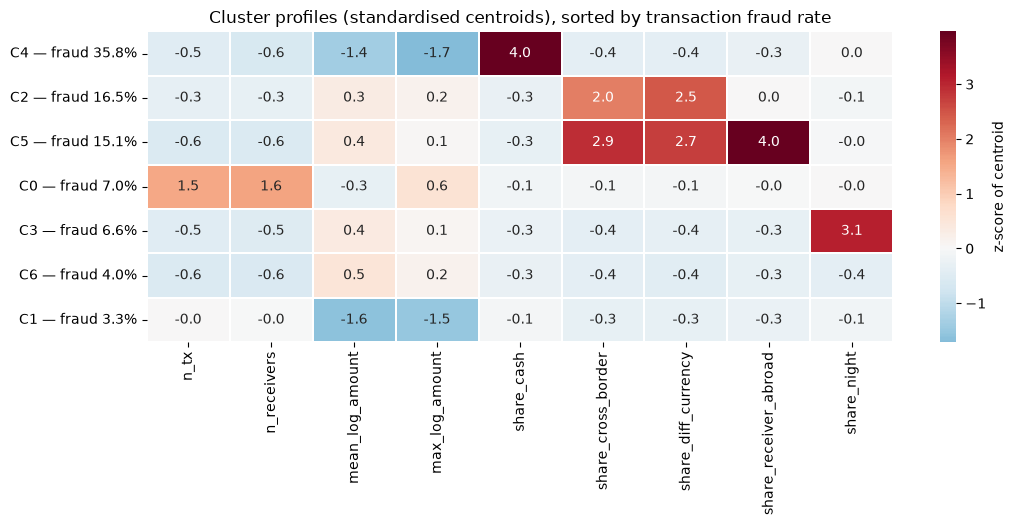

In [24]:
# Standardised cluster centroids: how each cluster deviates from the average sender
cent = pd.DataFrame(km.cluster_centers_, columns=CL_FEATURES)
order = profile.sort_values("tx_fraud_rate", ascending=False).index
cent = cent.loc[order]
cent.index = [f"C{c} — fraud {profile.loc[c, 'tx_fraud_rate']:.1%}" for c in order]
fig, ax = plt.subplots(figsize=(11, 0.55 * K + 1.5))
sns.heatmap(cent, cmap="RdBu_r", center=0, annot=True, fmt=".1f", linewidths=0.3, ax=ax,
            cbar_kws={"label": "z-score of centroid"})
ax.set_title("Cluster profiles (standardised centroids), sorted by transaction fraud rate")
plt.tight_layout(); plt.show()

With k = 7 (best silhouette), the clusters differ strongly in fraud rate even though the label was not used:

| Profile | Defining traits | Senders | Fraud rate |
|---|---|---|---|
| **Cash** | ~99% cash deposits/withdrawals, small amounts | ~2.4k | **35.8%** |
| **Inbound international** | cross-border with currency conversion, receiver mostly in the UK | ~2.6k | **16.5%** |
| **Outbound international** | cross-border to a receiver abroad | ~2.3k | **15.1%** |
| **Multi-transaction domestic** | ~5 transactions to ~5 receivers | ~10.6k | 7.0% |
| **Night-time** | ~90% of activity between 00:00 and 08:00 | ~2.8k | 6.6% |
| **One-off domestic** | single daytime UK→UK payment | ~19.9k | 4.0% |
| **Small-amount domestic** | domestic, low amounts | ~3.9k | 3.3% |

Cash and international senders are the risky profiles; plain domestic senders are low-risk.

## 7. Pre-processing

Besides the imputation described in section 2.1:
* Drop `transaction_id`; turn `date`/`time` into `hour`, `day_of_week`, `month` and `is_night`.
* Keep the `amount` outliers; add `log_amount` and `log_session_duration`.
* Add `diff_currency`, `diff_location`, `sender_abroad`, `receiver_abroad` and `is_cash`.
* Add sender, receiver and pair transaction counts.

Encoding, scaling and class-imbalance handling are left for the modelling stage.

In [25]:
def preprocess(raw: pd.DataFrame) -> pd.DataFrame:
    d = raw.copy()

    # 1-2. identifiers and timestamps
    d = d.drop(columns=["transaction_id"])
    ts = pd.to_datetime(d["date"] + " " + d["time"], format="%Y-%m-%d %H:%M:%S")
    d["hour"] = ts.dt.hour
    d["day_of_week"] = ts.dt.dayofweek
    d["month"] = ts.dt.month
    d["is_night"] = (d["hour"] < 8).astype(int)
    d["timestamp"] = ts
    d = d.drop(columns=["date", "time"])

    # 3. locations: GBP -> UK, otherwise Unknown
    for loc, cur in [("sender_bank_location", "payment_currency"), ("receiver_bank_location", "received_currency")]:
        miss = d[loc].isna()
        d[f"{loc}_missing"] = miss.astype(int)
        d.loc[miss & (d[cur] == "UK pounds"), loc] = "UK"
        d[loc] = d[loc].fillna("Unknown")

    # 4. payment type: Cross-border when the two (known) locations differ
    known_diff = ((d.sender_bank_location != d.receiver_bank_location)
                  & (d.sender_bank_location != "Unknown") & (d.receiver_bank_location != "Unknown"))
    miss = d["payment_type"].isna()
    d.loc[miss & known_diff, "payment_type"] = "Cross-border"
    d["payment_type"] = d["payment_type"].fillna("Unknown")

    # 5. channel
    d["transaction_channel"] = d["transaction_channel"].fillna("Unknown")

    # 6. amount: median per payment type + flag
    d["amount_missing"] = d["amount"].isna().astype(int)
    d["amount"] = d["amount"].fillna(d.groupby("payment_type")["amount"].transform("median"))
    d["amount"] = d["amount"].fillna(d["amount"].median())

    # 7. scores
    for c in ["account_activity_score", "device_risk_score"]:
        d[c] = d[c].fillna(d[c].median())

    # 8-9. transforms
    d["log_amount"] = np.log1p(d["amount"])
    d["log_session_duration"] = np.log1p(d["customer_session_duration"])

    # 10. international / cash indicators
    d["diff_currency"] = (d.payment_currency != d.received_currency).astype(int)
    d["diff_location"] = known_diff.astype(int)
    d["sender_abroad"] = (~d.sender_bank_location.isin(["UK", "Unknown"])).astype(int)
    d["receiver_abroad"] = (~d.receiver_bank_location.isin(["UK", "Unknown"])).astype(int)
    d["is_cash"] = d.payment_type.isin(["Cash Deposit", "Cash Withdrawal"]).astype(int)

    # 11. account-level aggregates (label-free; recompute leakage-safely when modelling)
    d["sender_tx_count"] = d.groupby("sender_id")["amount"].transform("size")
    d["sender_unique_receivers"] = d.groupby("sender_id")["receiver_id"].transform("nunique")
    d["receiver_tx_count"] = d.groupby("receiver_id")["amount"].transform("size")
    d["receiver_unique_senders"] = d.groupby("receiver_id")["sender_id"].transform("nunique")
    d["pair_tx_count"] = d.groupby(["sender_id", "receiver_id"])["amount"].transform("size")
    return d

clean = preprocess(df)
print("Shape after pre-processing:", clean.shape)
print("Remaining missing values:", int(clean.isna().sum().sum()))
clean.head()

Shape after pre-processing: (100459, 36)
Remaining missing values: 0


,sender_id,receiver_id,amount,payment_currency,received_currency,sender_bank_location,receiver_bank_location,payment_type,customer_session_duration,account_activity_score,transaction_channel,device_recognized,device_risk_score,verification_score,channel_flag,isFraud,hour,day_of_week,month,is_night,timestamp,sender_bank_location_missing,receiver_bank_location_missing,amount_missing,log_amount,log_session_duration,diff_currency,diff_location,sender_abroad,receiver_abroad,is_cash,sender_tx_count,sender_unique_receivers,receiver_tx_count,receiver_unique_senders,pair_tx_count
0,AA49C7A57304F7CF25AFC3B34,A1B80787BB81A17BCF1093FEA,971.580,UK pounds,UK pounds,UK,UK,ACH,200,40.000,POS,0,-1.161,-1.272,0,0,9,2,4,0,2023-04-19 09:44:51,0,0,0,6.880,5.303,0,0,0,0,0,4,4,1,1,1
1,AF929BA0C0E9FDF79640B04DB,AB88EA36C2764248B1083497E,56.000,UK pounds,UK pounds,UK,UK,ACH,308,62.300,Other,0,0.534,0.024,0,0,18,4,11,0,2022-11-11 18:47:13,0,0,0,4.043,5.733,0,0,0,0,0,8,8,1,1,1
2,A1F5681C7C087BB287F571BF9,A77801AFFD4C07AA5C581067B,"7,079.230",UK pounds,UK pounds,UK,UK,Credit card,211,31.000,Other,1,0.393,1.409,0,0,3,3,2,1,2023-02-09 03:00:23,0,0,0,8.865,5.357,0,0,0,0,0,3,2,2,1,2
3,AB298058402D02A7913DB3606,AB4371723703DB467AD2A1946,"25,042.780",UK pounds,UK pounds,UK,UK,ACH,99,21.200,Other,1,0.934,-2.564,0,0,13,4,4,0,2023-04-21 13:10:01,0,1,0,10.128,4.605,0,0,0,0,0,1,1,5,5,1
4,AECDF0440A068E3C82552C44C,A1CDD50184E01956054934B30,"4,580.900",Albanian lek,UK pounds,Albania,UK,Cross-border,85,29.800,Mobile App,1,0.219,2.443,0,1,16,6,3,0,2023-03-05 16:16:50,0,0,0,8.430,4.454,1,1,1,0,0,3,3,9,9,1


In [26]:
clean.to_csv("FinTx-Guard_train_clean.csv", index=False)
print("Saved FinTx-Guard_train_clean.csv")

Saved FinTx-Guard_train_clean.csv


## 8. Summary

* **Data quality:** no duplicates or invalid values; 7 columns with 3–10% missing values, imputed as in section 2.1. `amount` outliers are kept because they are mostly fraud.
* **Strongest signal:** account activity. Receivers with more than 10 transactions are 93% fraud, and pairs with 6 or more transactions are 100% fraud.
* **Risky transactions:** cash (27–35%), cross-border (18%), currency conversion (21%), destinations such as Nigeria, Morocco, Albania and the UAE (>30%), and extreme amounts.
* **Weak or no signal:** time of day, channel, device and behavioural scores.
* **Clustering:** cash and international sender profiles have 2–5× the base fraud rate.
* **For modelling:** handle the 1:12 imbalance and compute the account counts without leakage.